# Components of Time Series Decomposition

**Trend** is the long-term direction: going up, going down, or flat. Example: a company’s sales slowly growing over 5 years.

**Seasonality** is a pattern that repeats at a fixed, known interval. Example: ice cream sales peak every summer, and shop sales jump every Sunday or every Diwali.

**Cyclic pattern** is up-and-down waves with no fixed length, such as economic booms and recessions. They’re hard to predict, so beginners mostly treat them as part of the trend.

**Noise** (residual) is the random leftover that no pattern can explain. Every real series has some, and a good model should not try to predict it.

# TYpes of Decomposition

**Additive**: Value = Trend + Seasonality + Noise. Use it when the seasonal ups and downs stay about the same size over time.

**Multiplicative**: Value = Trend × Seasonality × Noise. Use it when the seasonal swings grow bigger as the level grows. 
    This is very common in sales data.


**Frequency** means how often data is recorded  ex- d(day) ,m(month) ,ms(monthly),q(quarterly), h(hourly)

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import yfinance as yf
import warnings
warnings.filterwarnings('ignore')

In [2]:
stock_data=yf.download("AAPL",start='2024-01-01', end="2024-12-30")

[*********************100%***********************]  1 of 1 completed


In [3]:
stock_data.head(10)

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2024-01-02,183.404022,186.170300,181.675100,184.895829,82488700
2024-01-03,182.030777,183.641149,181.220646,182.001140,58414500
2024-01-04,179.718933,180.884713,178.701340,179.956033,71983600
2024-01-05,178.997742,180.558713,177.999912,179.797998,62379700
2024-01-08,183.325012,183.364539,179.313915,179.896806,59144500
2024-01-09,182.910019,182.919893,180.529043,181.704712,42841800
2024-01-10,183.947388,184.154850,181.704725,182.129554,46792900
2024-01-11,183.354630,184.797051,181.408356,184.293184,49128400


In [4]:
stock_data.tail(10)

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2024-12-13,246.342285,247.493916,244.465903,246.034521,33155300
2024-12-16,249.231339,249.568900,245.865763,246.203325,51694800
2024-12-17,251.653748,252.001232,247.980408,248.278250,51356400
2024-12-18,246.262863,252.447973,245.955099,250.343252,56774100
2024-12-19,247.990295,250.184379,245.309752,245.716801,60882300
2024-12-20,252.656479,253.162799,243.919877,246.252937,147495300
2024-12-23,253.430847,253.808099,251.623953,252.934450,40858800
2024-12-24,256.339722,256.349629,253.450669,253.649240,23234700


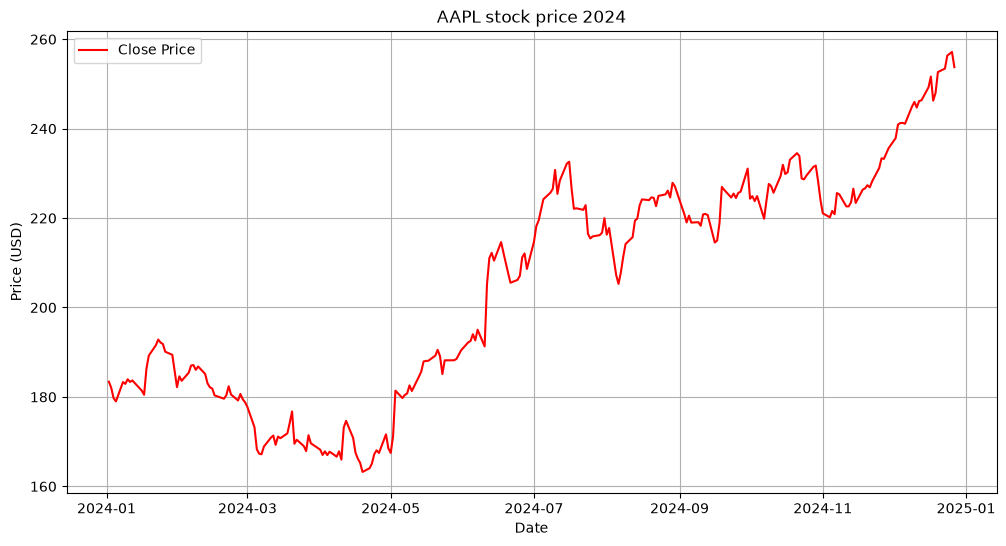

In [5]:
plt.figure(figsize=(12,6))
plt.plot(stock_data.index,stock_data['Close'],label='Close Price',color="red")
plt.title("AAPL stock price 2024")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
stock_data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 250 entries, 2024-01-02 to 2024-12-27
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   250 non-null    float64
 1   (High, AAPL)    250 non-null    float64
 2   (Low, AAPL)     250 non-null    float64
 3   (Open, AAPL)    250 non-null    float64
 4   (Volume, AAPL)  250 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.7 KB


# Classical Time Series Decomposition

In [7]:
from statsmodels.tsa.seasonal import seasonal_decompose
decomposition_additive=seasonal_decompose(stock_data['Close'],model="additive",period=30)

In [8]:
trend_additive=decomposition_additive.trend
seasonal_additive=decomposition_additive.seasonal
residual_additive=decomposition_additive.resid

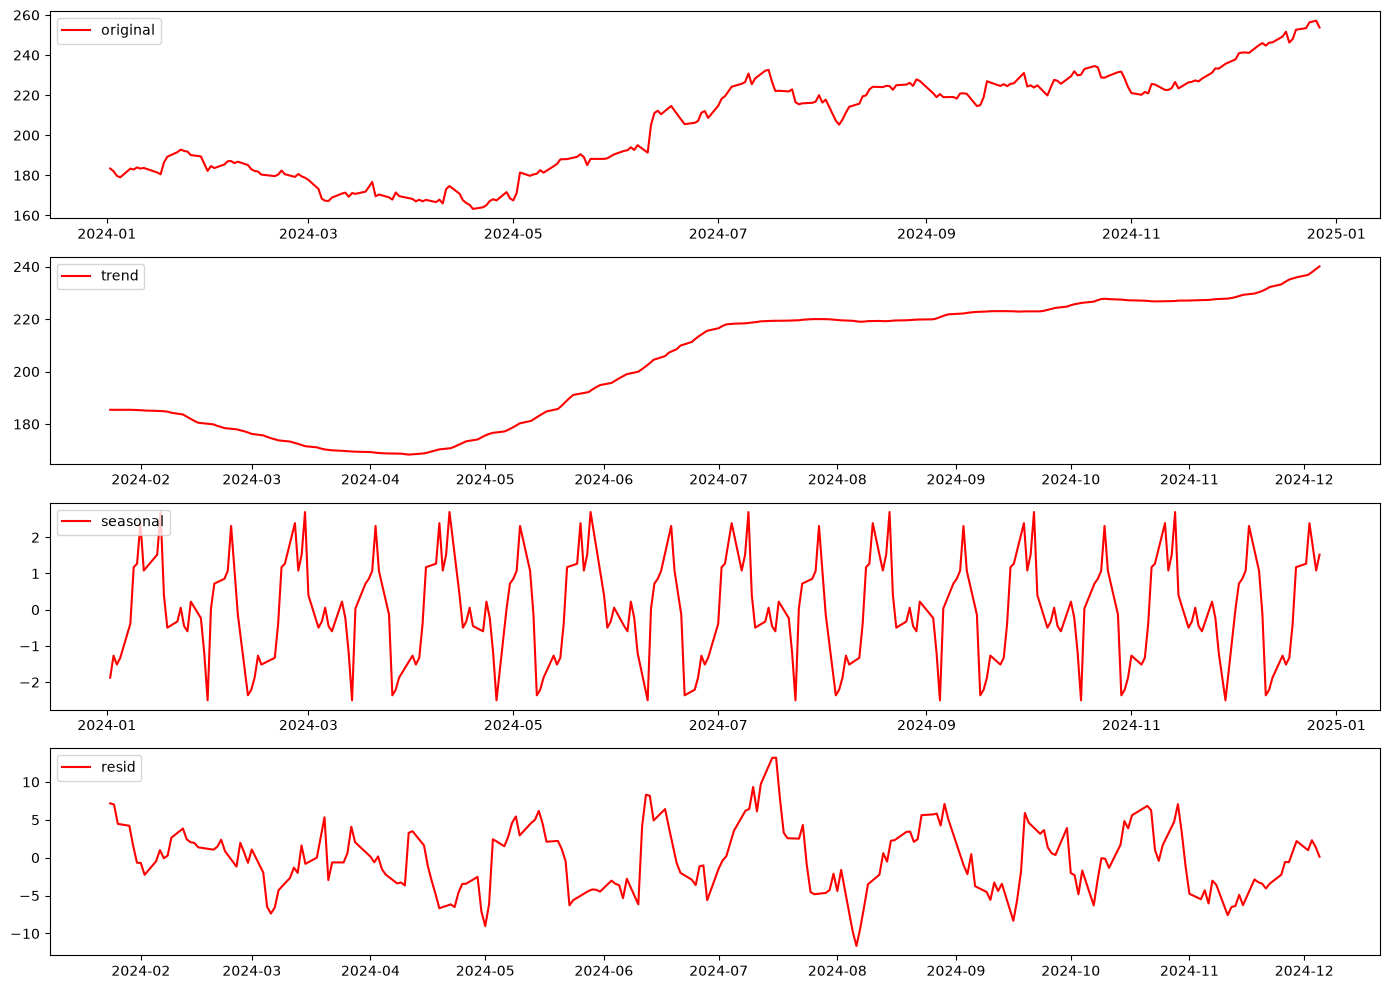

In [9]:
plt.figure(figsize=(14,10))

plt.subplot(4,1,1)
plt.plot(stock_data['Close'],label="original",color='red')
plt.legend(loc="upper left")

plt.subplot(4,1,2)
plt.plot(trend_additive,label="trend",color='red')
plt.legend(loc="upper left")

plt.subplot(4,1,3)
plt.plot(seasonal_additive,label="seasonal",color='red')
plt.legend(loc="upper left")

plt.subplot(4,1,4)
plt.plot(residual_additive,label="resid",color='red')
plt.legend(loc="upper left")

plt.tight_layout()

           


In [10]:


# Make Close a simple Series (yfinance gives AAPL as a 2nd column level)
close = stock_data['Close'].squeeze()

print(close.index.dtype)                     # should say datetime64[ns]
print(close.index.is_monotonic_increasing)   # should be True (dates in order)

datetime64[s]
True


In [11]:
close.index.year          # 2024
close.index.month         # 1 to 12
close.index.day           # day of month
close.index.dayofweek     # 0 = Monday ... 4 = Friday
close.index.day_name()    # 'Monday', 'Tuesday', ...
close.index.quarter       # 1 to 4
close.index.dayofyear     # 1 to 366
close.index.is_month_end  # True/False

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,  True, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False,  True, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False,  True, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,

In [12]:
parts = pd.DataFrame({
    'close':     close,
    'year':      close.index.year,
    'month':     close.index.month,
    'weekday':   close.index.day_name(),
    'dayofweek': close.index.dayofweek,
    'quarter':   close.index.quarter,
})
parts.head()

,close,year,month,weekday,dayofweek,quarter
Date,,,,,,
2024-01-02,183.404022,2024,1,Tuesday,1,1
2024-01-03,182.030777,2024,1,Wednesday,2,1
2024-01-04,179.718933,2024,1,Thursday,3,1
2024-01-05,178.997742,2024,1,Friday,4,1
2024-01-08,183.325012,2024,1,Monday,0,1
